## **DATA 620 - Project Two**
## **A Bipartite Network Analysis of Last.fm User-Artist Listening Relationships**
## **Brandon Chanderban**

## Project Overview

For this project, the Last.fm music listening dataset from the HetRec 2011 collection will be examined, which contains information concerning the relationships between users and artists. The dataset represents a bipartite network wherein users and artists constitute two distinct groups of nodes, with edges representing recorded listening relationships between them. Each edge possesses a weight corresponding to the number of times a particular user listened to an artist.

The analysis will examine the structure of this network and apply the island method discussed by Tsvetovat and Kouznetsov (2011) to progressively reduce its size by removing weaker connections. Following this, the characteristics of both groups will be investigated, including patterns of user engagement, artist popularity, as well as the relationships that remain following the reduction of the network.




## Import Libraries and Load Datasets

In [20]:
# Load the required libraries.
import pandas as pd
import networkx as nx
from networkx.algorithms import bipartite
import matplotlib.pyplot as plt
import numpy as np

# Load the Last.fm user-artist and artist information from GitHub.
user_artists_url = "https://raw.githubusercontent.com/bkchanderban/CUNY_SPS/refs/heads/main/DATA620/Project_Two/user_artists.dat"

artists_url = "https://raw.githubusercontent.com/bkchanderban/CUNY_SPS/refs/heads/main/DATA620/Project_Two/artists.dat"

# Read both tab-separated datasets into pandas DataFrames.
user_artists = pd.read_csv(user_artists_url, sep='\t')
artists = pd.read_csv(artists_url, sep='\t')

print("Both datasets have successfully been loaded.")

Both datasets have successfully been loaded.


### Inspect the Imported Datasets

In [21]:
# Display the first five rows of the user-artist dataset.
display(user_artists.head())

,userID,artistID,weight
0,2,51,13883
1,2,52,11690
2,2,53,11351
3,2,54,10300
4,2,55,8983


In [22]:
# Display the first five rows of the artist information dataset.
display(artists.head())

,id,name,url,pictureURL
0,1,MALICE MIZER,http://www.last.fm/music/MALICE+MIZER,http://userserve-ak.last.fm/serve/252/10808.jpg
1,2,Diary of Dreams,http://www.last.fm/music/Diary+of+Dreams,http://userserve-ak.last.fm/serve/252/3052066.jpg
2,3,Carpathian Forest,http://www.last.fm/music/Carpathian+Forest,http://userserve-ak.last.fm/serve/252/40222717...
3,4,Moi dix Mois,http://www.last.fm/music/Moi+dix+Mois,http://userserve-ak.last.fm/serve/252/54697835...
4,5,Bella Morte,http://www.last.fm/music/Bella+Morte,http://userserve-ak.last.fm/serve/252/14789013...


In [23]:
# Display the dimensions and column names of both datasets.
print("The shape of the user-artist dataset is:", user_artists.shape)
print("The user-artist columns are:", user_artists.columns.to_list())

print("\nThe shape of the artist dataset shape is:", artists.shape)
print("The artist columns are:", artists.columns.to_list())

# Check for missing values.
print("\nThe number of missing values in the user-artist dataset is:", user_artists.isnull().sum().sum())
print("\nThe number of missing values in the artist dataset is:", artists.isnull().sum().sum())
print("The artists dataset missing values by columns:")
print(artists.isnull().sum())

The shape of the user-artist dataset is: (92834, 3)
The user-artist columns are: ['userID', 'artistID', 'weight']

The shape of the artist dataset shape is: (17632, 4)
The artist columns are: ['id', 'name', 'url', 'pictureURL']

The number of missing values in the user-artist dataset is: 0

The number of missing values in the artist dataset is: 444
The artists dataset missing values by columns:
id              0
name            0
url             0
pictureURL    444
dtype: int64


From the initial dataset inspection, the user-artist dataset contains 92,834 observations across its three columns, representing individual users, musical artists, and their associated listening counts. Meanwhile, the artist information dataset contains 17,632 records across its four columns, allowing us to identify the artists associated with the numerical identifiers in the primary dataset.

With respect to data completeness, no missing values were identified in the user-artist dataset, whilst 444 missing values were observed in the pictureURL column of the artist dataset. As these URLs are not required for the intended network analysis, the missing values should not affect the construction or subsequent examination of the bipartite network.

## Construct the Bipartite Network

Subsequently, NetworkX will be utilized to construct the user-artist network, ensuring that users and artists are represented as separate node groups.

In [24]:
# Initialize an undirected graph for the bipartite network.
G = nx.Graph()

# Add users as the first group of nodes.
for user in user_artists["userID"].unique():
    G.add_node(f"user_{user}", bipartite=0, node_type="User")

# Add artists as the second group, including their names.
for _, row in artists.iterrows():
    G.add_node(
        f"artist_{row['id']}",
        bipartite=1,
        node_type="Artist",
        name=row["name"]
    )

# Add weighted connections between users and artists.
for _, row in user_artists.iterrows():
    G.add_edge(
        f"user_{row['userID']}",
        f"artist_{row['artistID']}",
        weight=row["weight"]
    )

### Verify the Bipartite Structure

In [25]:
# Verify that all connections occur between the two distinct node groups.


print("Is the network a bipartite one?", bipartite.is_bipartite(G))

# Display the number of nodes and edges.
print("\nThe number of nodes in the network is:", G.number_of_nodes())
print("The number of edges in the network is:", G.number_of_edges())

# Count the number of nodes belonging to each group.
users = {n for n, d in G.nodes(data=True) if d["bipartite"] == 0}
artist_nodes = {n for n, d in G.nodes(data=True) if d["bipartite"] == 1}

print("\nThe number of users in the network is:", len(users))
print("The number of artists in the network is:", len(artist_nodes))

Is the network a bipartite one? True

The number of nodes in the network is: 19524
The number of edges in the network is: 92834

The number of users in the network is: 1892
The number of artists in the network is: 17632


### Display Sample Weighted Relationships

In [26]:
# Inspect the first five weighted relationships within the network.
for user, artist, data in list(G.edges(data=True))[:5]:
    print(f"{user} is listening to {artist} {data['weight']} times.")

user_2 is listening to artist_51 13883 times.
user_2 is listening to artist_52 11690 times.
user_2 is listening to artist_53 11351 times.
user_2 is listening to artist_54 10300 times.
user_2 is listening to artist_55 8983 times.


The constructed network contains 19,524 nodes, representing 1,892 users and 17,632 musical artists, connected through 92,834 weighted listening relationships. The bipartite verification returned True, confirming that the network's edges connect users to artists rather than nodes belonging to the same group (such as user to user).

Furthermore, the sample relationships demonstrate that the listening counts have been preserved as edge weights, allowing us to distinguish between weaker and stronger user-artist connections. This will provide the foundation for subsequently reducing the network through the island method.

## Examine the Original Network

Prior to applying the island method, we will examine several characteristics of the original bipartite network, including the distribution of connections amongst several users and artists, as well as the strength of their listening relationships. These measures will help establish a baseline against which the reduced network can subsequently be compared.

### Network Degree Statistics

In [27]:
# Calculate the degree of each user and artist.
user_degrees = [G.degree(user) for user in users]
artist_degrees = [G.degree(artist) for artist in artist_nodes]

# Display descriptive statistics for both groups.
print("User Degree Statistics:")
print(pd.Series(user_degrees).describe())

print("\nArtist Degree Statistics:")
print(pd.Series(artist_degrees).describe())

User Degree Statistics:
count    1892.000000
mean       49.066596
std         5.845879
min         1.000000
25%        50.000000
50%        50.000000
75%        50.000000
max        50.000000
dtype: float64

Artist Degree Statistics:
count    17632.000000
mean         5.265086
std         20.620315
min          1.000000
25%          1.000000
50%          1.000000
75%          3.000000
max        611.000000
dtype: float64


### Listening-Count Statistics

In [28]:
# Examine the distribution of listening counts across user-artist relationships.
print("Listening Count Statistics:")
print(user_artists["weight"].describe())

# Display additional percentiles to help identify suitable island thresholds.
print("\nAdditional Listening Count Percentiles:")
print(user_artists["weight"].quantile([0.50, 0.75, 0.90, 0.95, 0.99]))

Listening Count Statistics:
count     92834.00000
mean        745.24393
std        3751.32208
min           1.00000
25%         107.00000
50%         260.00000
75%         614.00000
max      352698.00000
Name: weight, dtype: float64

Additional Listening Count Percentiles:
0.50     260.00
0.75     614.00
0.90    1387.00
0.95    2328.00
0.99    7228.01
Name: weight, dtype: float64


### Identify Prominent Artists

In [29]:
# Calculate the number of distinct listeners and total listening counts per artist.
artist_summary = (
    user_artists.groupby("artistID")
    .agg(
        distinct_listeners=("userID", "nunique"),
        total_listens=("weight", "sum")
    )
    .reset_index()
)

# Add recognizable artist names.
artist_summary = artist_summary.merge(
    artists[["id", "name"]],
    left_on="artistID",
    right_on="id",
    how="left"
)

# Display the ten artists with the greatest number of distinct listeners.
top_artists = artist_summary.sort_values(
    "distinct_listeners", ascending=False
).head(10)

display(top_artists[["name", "distinct_listeners", "total_listens"]])

,name,distinct_listeners,total_listens
83,Lady Gaga,611,1291387
283,Britney Spears,522,2393140
282,Rihanna,484,905423
221,The Beatles,480,662116
294,Katy Perry,473,532545
61,Madonna,429,921198
327,Avril Lavigne,417,525844
286,Christina Aguilera,407,1058405
184,Muse,400,485076
492,Paramore,399,963449


The preliminary results reveal considerable variation in network connectivity and listening activity. Users have an average degree of approximately 49, whilst artists possess an average degree of 5.27, with half of all artists connected to only one user. It should also be noted that the majority of users possess a degree of 50, suggesting a potential limitation in the number of artist relationships represented per user within the dataset. Moreover, listening counts exhibit a positively skewed distribution, with a median of 260 compared to a mean of approximately 745, indicating that certain user-artist relationships account for substantially greater listening activity than others.

Amongst the most widely connected artists are Lady Gaga, Britney Spears, Rihanna, and The Beatles. Interestingly, whilst Lady Gaga possesses the greatest number of distinct listeners, Britney Spears accumulates a higher total listening count. This highlights the distinction between the breadth and intensity of user engagement, which we can investigate further through network reduction.

## Visualize the Original Network

Given the considerable size of the original bipartite network, comprising 19,524 nodes and 92,834 edges, visualizing the entire network would likely produce an overcrowded and difficult-to-interpret diagram. As such, we will extract a smaller subgraph containing selected users and prominent musical artists to illustrate the relationships between the two distinct groups. This visualization will provide an initial representation of the network's structure before proceeding with the island method to identify and examine stronger listening relationships.

### Extract a Sample Bipartite Subgraph

In [30]:
# Identify the five artists with the greatest number of distinct listeners.
top_artist_ids = artist_summary.nlargest(
    5, "distinct_listeners"
)["artistID"].tolist()

# Identify their corresponding nodes in the network.
selected_artists = [f"artist_{artist_id}" for artist_id in top_artist_ids]

# Find users connected to at least one of these artists.
connected_users = set()

for artist in selected_artists:
    connected_users.update(G.neighbors(artist))

# Select ten users with the most connections to the five artists.
selected_users = sorted(
    connected_users,
    key=lambda user: (
        -sum(G.has_edge(user, artist) for artist in selected_artists),
        user
    )
)[:10]

# Extract a subgraph containing the selected users and artists.
sample_nodes = selected_users + selected_artists
sample_graph = G.subgraph(sample_nodes).copy()

print("The number of nodes in the sample is:", sample_graph.number_of_nodes())
print("The number of edges in the sample is:", sample_graph.number_of_edges())
print("Is the sample bipartite?", bipartite.is_bipartite(sample_graph))

The number of nodes in the sample is: 15
The number of edges in the sample is: 50
Is the sample bipartite? True


### Visualize the Sample Network

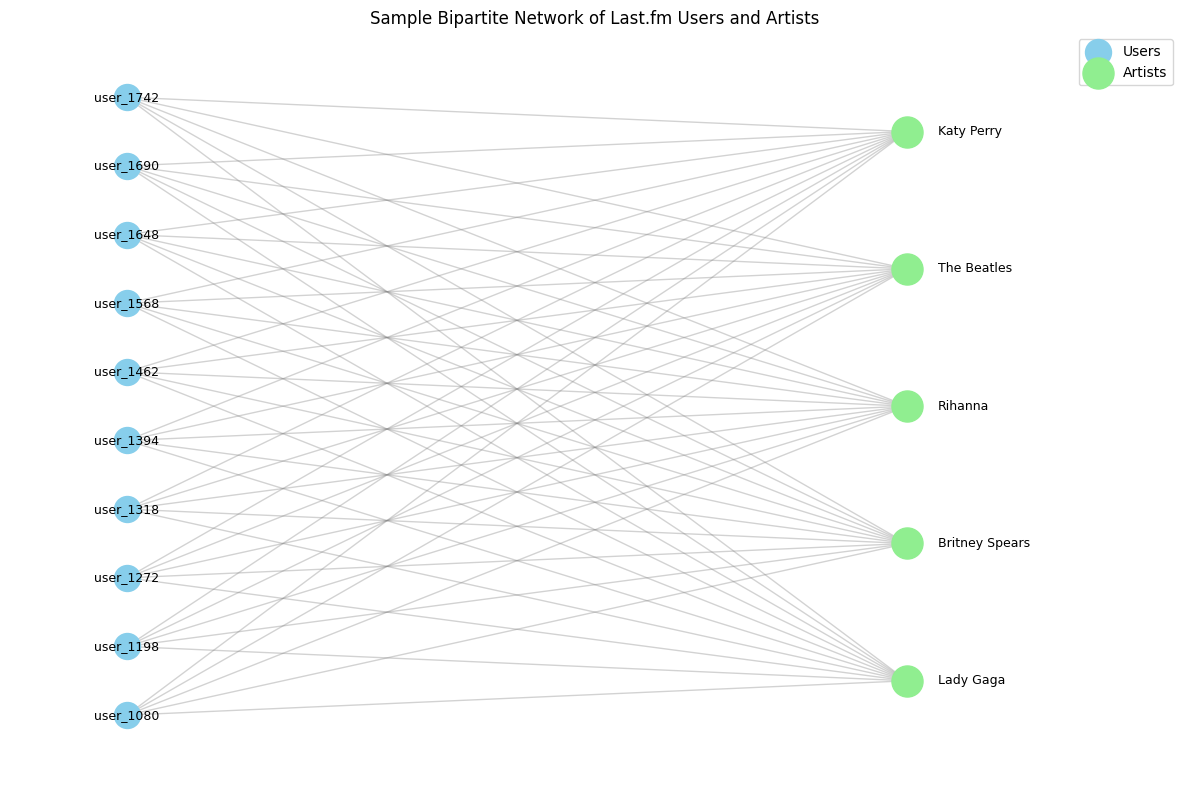

In [31]:
# Position users and artists in separate columns.
pos = {}

for i, user in enumerate(selected_users):
    pos[user] = (0, i)

for i, artist in enumerate(selected_artists):
    pos[artist] = (1, i * 2 + 0.5)

plt.figure(figsize=(12, 8))

# Draw user nodes.
nx.draw_networkx_nodes(
    sample_graph,
    pos,
    nodelist=selected_users,
    node_color="skyblue",
    node_size=350,
    label="Users"
)

# Draw artist nodes.
nx.draw_networkx_nodes(
    sample_graph,
    pos,
    nodelist=selected_artists,
    node_color="lightgreen",
    node_size=500,
    label="Artists"
)

# Draw the connections between users and artists.
nx.draw_networkx_edges(
    sample_graph,
    pos,
    edge_color="gray",
    alpha=0.35,
    width=1.0
)

# Display anonymous user identifiers centered on their nodes.
user_labels = {user: user for user in selected_users}

nx.draw_networkx_labels(
    sample_graph,
    pos,
    labels=user_labels,
    font_size=9,
    horizontalalignment="center"
)

# Position recognizable artist names slightly to the right.
artist_labels = {
    artist: sample_graph.nodes[artist]["name"]
    for artist in selected_artists
}

artist_label_pos = {
    artist: (pos[artist][0] + 0.04, pos[artist][1])
    for artist in selected_artists
}

nx.draw_networkx_labels(
    sample_graph,
    artist_label_pos,
    labels=artist_labels,
    font_size=9,
    horizontalalignment="left"
)

# Add the title and legend.
plt.title("Sample Bipartite Network of Last.fm Users and Artists")
plt.legend(loc="upper right")

# Provide additional space for the artist labels.
plt.xlim(-0.15, 1.35)

plt.axis("off")
plt.tight_layout()
plt.show()

The visualization illustrates a selected portion of the original bipartite network, comprising ten users and five prominent musical artists. The two groups are clearly distinguishable, with edges representing recorded listening relationships between users and artists. Several users share connections with the same artists, demonstrating how individual listening preferences can create overlapping relationships within the network.


It should be noted that this subgraph was deliberately constructed around highly connected artists and selected users, rather than being a random sample of the entire network. Consequently, its relatively dense structure should not be interpreted as representative of all user–artist relationships within the dataset.

## Apply the Island Method

To reduce the size of the original network, we will apply the island method outlined by Tsvetovat and Kouznetsov (2011). This approach progressively removes edges with weights at or below a specified threshold, allowing stronger relationships to remain whilst potentially separating the network into smaller connected components.

In this analysis, the edge weights represent the number of times individual users listened to particular artists. As such, we will examine several thresholds informed by the observed distribution of listening counts, allowing us to evaluate how the network changes as weaker listening relationships are removed.

### Define the Island-Method Function


In [32]:
# Define a function to retain relationships above a specified listening threshold.
def trim_edges(graph, threshold):
    reduced_graph = nx.Graph()

    for u, v, data in graph.edges(data=True):
        if data["weight"] > threshold:
            reduced_graph.add_node(u, **graph.nodes[u])
            reduced_graph.add_node(v, **graph.nodes[v])
            reduced_graph.add_edge(u, v, **data)

    return reduced_graph

# Define several thresholds based on the listening-count distribution.
thresholds = [0, 260, 614, 1387, 2328, 7229]

# Apply the island method at each threshold.
islands = {}

for threshold in thresholds:
    islands[threshold] = trim_edges(G, threshold)

print("The island method has been applied successfully.")

The island method has been applied successfully.


### Examine the Network Reduction Across Thresholds

In [33]:
# Compare the network structure at each listening-count threshold.
reduction_results = []

for threshold, graph in islands.items():
    components = list(nx.connected_components(graph))

    # Count the number of users and artists remaining.
    remaining_users = sum(
        1 for _, data in graph.nodes(data=True)
        if data["bipartite"] == 0
    )

    remaining_artists = sum(
        1 for _, data in graph.nodes(data=True)
        if data["bipartite"] == 1
    )

    reduction_results.append({
        "Threshold": threshold,
        "Users": remaining_users,
        "Artists": remaining_artists,
        "Nodes": graph.number_of_nodes(),
        "Edges": graph.number_of_edges(),
        "Components": len(components),
        "Largest Component": max(
            (len(component) for component in components),
            default=0
        )
    })

# Display the reduction results as a DataFrame.
reduction_df = pd.DataFrame(reduction_results)

display(reduction_df)

,Threshold,Users,Artists,Nodes,Edges,Components,Largest Component
0,0,1892,17632,19524,92834,8,19507
1,260,1734,9558,11292,46309,22,11211
2,614,1574,5572,7146,23182,35,7045
3,1387,1292,2820,4112,9275,60,3985
4,2328,1020,1676,2696,4641,67,2541
5,7229,456,394,850,928,79,653


The results demonstrate a substantial reduction in network size as the minimum listening-count threshold increases. At the 2,328-listen threshold, corresponding approximately to the 95th percentile, the network is reduced from 19,524 nodes and 92,834 edges to 2,696 nodes and 4,641 edges. Meanwhile, the number of connected components increases from 8 to 67, indicating that removing weaker listening relationships has separated portions of the original network into smaller components.

However, the largest remaining component still contains 2,541 nodes, suggesting that a substantial proportion of the surviving users and artists remain interconnected. As such, the 2,328-listen threshold will be selected for further examination, as it considerably reduces network complexity whilst retaining sufficient relationships for meaningful analysis.

## Further Examine the Reduced Network

Having applied the island method, we will now examine the network retained at the 2,328-listen threshold. In particular, the analysis will identify the musical artists with the greatest number of remaining listener connections, alongside the users maintaining the broadest range of strong listening relationships. These findings will help us understand the characteristics of both distinct groups following network reduction.

### Identify Prominent Artists in the Reduced Network

In [34]:
# Select the reduced network at the 2,328-listen threshold.
reduced_G = islands[2328]

# Calculate the remaining user connections for each artist.
reduced_artist_degrees = {
    node: reduced_G.degree(node)
    for node, data in reduced_G.nodes(data=True)
    if data["bipartite"] == 1
}

# Identify the ten artists with the most retained connections.
top_reduced_artists = sorted(
    reduced_artist_degrees.items(),
    key=lambda item: item[1],
    reverse=True
)[:10]

# Prepare the results with recognizable artist names.
reduced_artist_results = pd.DataFrame([
    {
        "Artist": reduced_G.nodes[node]["name"],
        "Strong Listener Connections": degree
    }
    for node, degree in top_reduced_artists
])

display(reduced_artist_results)

,Artist,Strong Listener Connections
0,Britney Spears,156
1,Lady Gaga,122
2,Christina Aguilera,84
3,Madonna,83
4,Depeche Mode,69
5,Rihanna,69
6,The Beatles,63
7,Paramore,57
8,Kylie Minogue,46
9,Muse,46


### Examine Users in the Reduced Network

In [35]:
reduced_user_degrees = {
    node: reduced_G.degree(node)
    for node, data in reduced_G.nodes(data=True)
    if data["bipartite"] == 0
}

# Identify the ten users with the most retained artist connections.
top_reduced_users = sorted(
    reduced_user_degrees.items(),
    key=lambda item: item[1],
    reverse=True
)[:10]

# Prepare the user results.
reduced_user_results = pd.DataFrame(
    top_reduced_users,
    columns=["User", "Strong Artist Connections"]
)

display(reduced_user_results)

,User,Strong Artist Connections
0,user_387,50
1,user_1942,45
2,user_1195,42
3,user_734,40
4,user_2000,40
5,user_455,38
6,user_1504,37
7,user_107,36
8,user_1111,34
9,user_104,33


Following the application of the 2,328-listen threshold, several prominent artists retain substantial connections with highly engaged listeners. Britney Spears leads with 156 remaining user connections, followed by Lady Gaga with 122 and Christina Aguilera with 84. Interestingly enough, Britney Spears overtakes Lady Gaga, who previously possessed the greatest number of distinct listeners, suggesting that her audience within this dataset demonstrates comparatively stronger listening engagement.


With respect to the user group, User 387 retains connections with 50 artists above the selected threshold, followed by User 1942 with 45 and User 1195 with 42. These findings indicate that certain users maintain high listening counts across multiple artists, whilst others may demonstrate more concentrated listening patterns. As such, the reduced network provides further insight into the intensity of engagement amongst both groups.

## Visualize the Reduced Bipartite Network

To illustrate the effects of the island method, we will visualize a selected portion of the network retained at the 2,328-listen threshold. The visualization will focus on prominent artists and users connected to them, preserving only relationships exceeding the selected listening-count threshold. This will allow us to examine the structure of stronger listening relationships and compare the reduced network with the earlier visualization.

### Extract the Reduced-Network Subgraph

In [36]:
# Identify the five artists with the most retained listener connections.
top_reduced_artist_nodes = [
    node for node, degree in top_reduced_artists[:5]
]

# Find users connected to the selected artists in the reduced network.
connected_reduced_users = set()

for artist in top_reduced_artist_nodes:
    connected_reduced_users.update(reduced_G.neighbors(artist))

# Select ten users with the most retained connections to these artists.
selected_reduced_users = sorted(
    connected_reduced_users,
    key=lambda user: (
        -sum(reduced_G.has_edge(user, artist)
             for artist in top_reduced_artist_nodes),
        user
    )
)[:10]

# Extract the reduced subgraph.
reduced_sample_nodes = selected_reduced_users + top_reduced_artist_nodes
reduced_sample = reduced_G.subgraph(reduced_sample_nodes).copy()

print("Number of nodes in the reduced sample:", reduced_sample.number_of_nodes())
print("Number of edges in the reduced sample:", reduced_sample.number_of_edges())
print("Is the reduced sample bipartite?", bipartite.is_bipartite(reduced_sample))

Number of nodes in the reduced sample: 15
Number of edges in the reduced sample: 40
Is the reduced sample bipartite? True


### Visualize the Reduced Network

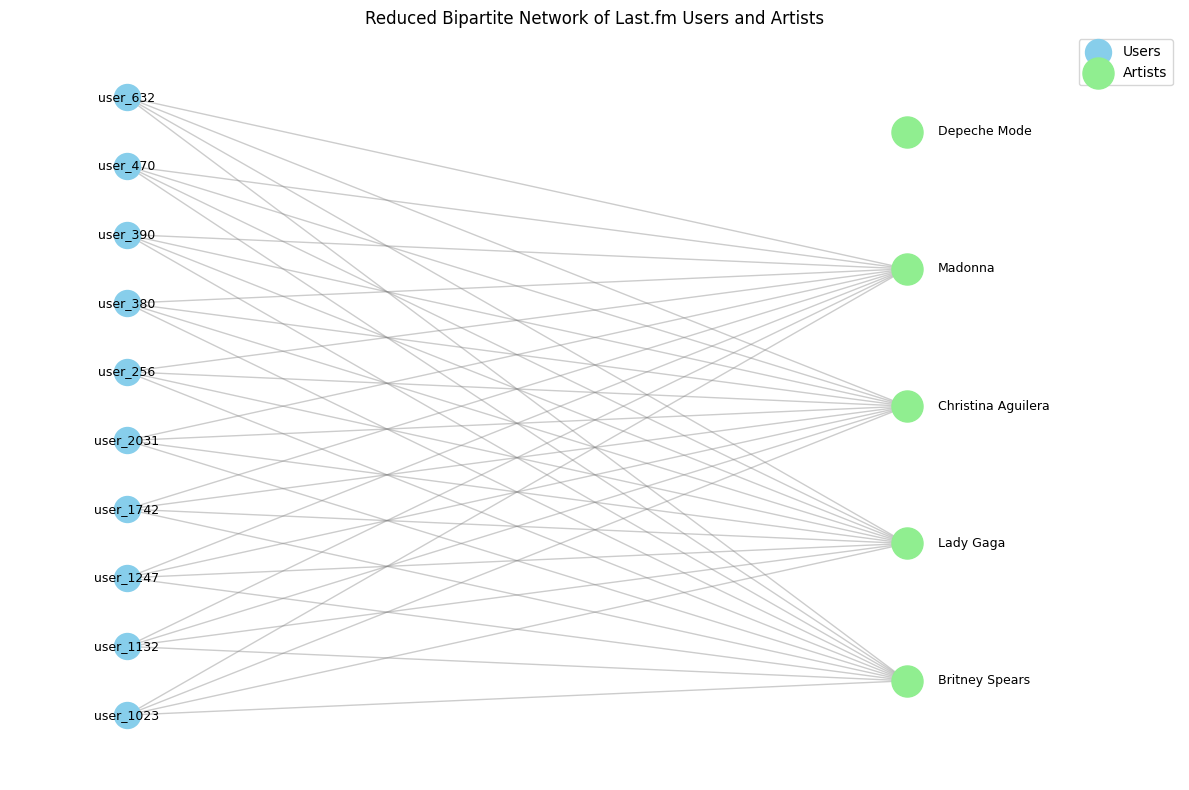

In [37]:
# Position the selected users and artists in separate columns.
reduced_pos = {}

for i, user in enumerate(selected_reduced_users):
    reduced_pos[user] = (0, i)

for i, artist in enumerate(top_reduced_artist_nodes):
    reduced_pos[artist] = (1, i * 2 + 0.5)

plt.figure(figsize=(12, 8))

# Draw user nodes.
nx.draw_networkx_nodes(
    reduced_sample,
    reduced_pos,
    nodelist=selected_reduced_users,
    node_color="skyblue",
    node_size=350,
    label="Users"
)

# Draw artist nodes.
nx.draw_networkx_nodes(
    reduced_sample,
    reduced_pos,
    nodelist=top_reduced_artist_nodes,
    node_color="lightgreen",
    node_size=500,
    label="Artists"
)

# Draw only the relationships retained after island reduction.
nx.draw_networkx_edges(
    reduced_sample,
    reduced_pos,
    edge_color="gray",
    alpha=0.4,
    width=1.0
)

# Display anonymous user identifiers.
user_labels = {
    user: user for user in selected_reduced_users
}

nx.draw_networkx_labels(
    reduced_sample,
    reduced_pos,
    labels=user_labels,
    font_size=9,
    horizontalalignment="center"
)

# Display artist names beside their nodes.
artist_labels = {
    artist: reduced_sample.nodes[artist]["name"]
    for artist in top_reduced_artist_nodes
}

artist_label_pos = {
    artist: (reduced_pos[artist][0] + 0.04, reduced_pos[artist][1])
    for artist in top_reduced_artist_nodes
}

nx.draw_networkx_labels(
    reduced_sample,
    artist_label_pos,
    labels=artist_labels,
    font_size=9,
    horizontalalignment="left"
)

# Add the title and legend.
plt.title("Reduced Bipartite Network of Last.fm Users and Artists")
plt.legend(loc="upper right")
plt.xlim(-0.15, 1.35)
plt.axis("off")
plt.tight_layout()
plt.show()

The visualization presents a selected portion of the reduced bipartite network, comprising ten users and five musical artists connected through 40 relationships exceeding the 2,328-listen threshold. The network remains bipartite, with users and artists represented as distinct groups, whilst the retained connections demonstrate comparatively strong listening engagement amongst the selected individuals.

Notably, artists such as Britney Spears, Lady Gaga, Christina Aguilera, Madonna, and Depeche Mode continue to share connections with several users, demonstrating overlapping patterns of intensive listening activity. However, as this visualization focuses on selected prominent artists and their associated users, it should not be interpreted as representative of the entire reduced network. Furthermore, as the original and reduced visualizations feature independently selected nodes, their differences should not be attributed exclusively to the removal of weaker relationships.

## Additional Analysis: Examine the Islands within the Reduced Network

Following the application of the island method, the reduced network contains 67 connected components. To further examine the results of this reduction, we will identify the largest components and compare their sizes. This will allow us to assess whether the surviving relationships are distributed across several substantial groups or remain concentrated within a single dominant component.

### Examine Component Sizes

In [38]:
# Identify connected components in the reduced network.
components = sorted(
    nx.connected_components(reduced_G),
    key=len,
    reverse=True
)

# Calculate the sizes of the ten largest components.
component_sizes = [
    len(component) for component in components[:10]
]

# Display the results.
component_df = pd.DataFrame({
    "Component": range(1, len(component_sizes) + 1),
    "Number of Nodes": component_sizes
})

display(component_df)

,Component,Number of Nodes
0,1,2541
1,2,13
2,3,4
3,4,4
4,5,3
5,6,3
6,7,3
7,8,3
8,9,3
9,10,3


The component-size analysis reveals that the reduced network remains dominated by one large connected component containing 2,541 of the 2,696 surviving nodes, or approximately 94.3%. By comparison, the second-largest component contains only 13 nodes, whilst the remaining components are considerably smaller.


These findings suggest that, despite the removal of weaker listening relationships, most surviving users and artists remain interconnected through shared listening activity. Nevertheless, the presence of several smaller components demonstrates that certain groups of users and artists are disconnected from the dominant network at the selected threshold. This further illustrates how the island method can reveal differences in connectivity amongst strongly weighted relationships.

## Conclusion

This project examined a bipartite network of Last.fm users and musical artists, comprising 19,524 nodes and 92,834 weighted listening relationships. Through the application of the island method, the network was progressively reduced by removing connections with lower listening counts. At the selected threshold of 2,328 listens, the network retained 2,696 nodes and 4,641 edges, representing a substantial reduction in its original size.

The findings revealed differences in both the breadth and intensity of listening engagement. Whilst certain artists attracted a greater number of distinct listeners, others retained comparatively stronger connections following network reduction. Similarly, some users maintained substantial listening activity across numerous artists, illustrating differences in individual engagement patterns. Furthermore, the component analysis demonstrated that most surviving nodes remained interconnected within one dominant component, despite the emergence of several smaller islands.

As such, the analysis demonstrates how weighted bipartite networks and the island method can be utilized to identify stronger relationships and investigate the structural characteristics of two distinct groups. However, the findings are limited to the historical Last.fm sample and should not be interpreted as representative of present-day listening behavior or broader musical preferences.

## References

Cantador, I., Brusilovsky, P., & Kuflik, T. (2011). Second workshop on information heterogeneity and fusion in recommender systems (HetRec 2011). In *Proceedings of the fifth ACM conference on Recommender systems* (pp. 387–388). Association for Computing Machinery.

GroupLens Research. (2011). *HetRec 2011 datasets* [Data set]. https://grouplens.org/datasets/hetrec-2011/

Tsvetovat, M., & Kouznetsov, A. (2011). *Social network analysis for startups: Finding connections on the social web*. O'Reilly Media.